# Can a straddling window see above the block it contains? -- 2026-11-03

**hshunt's question.** *"When there are pixels that see part of two different grammar rules they
may be able to check for consistency between blocks in a way the block aligned model cannot. It is
a small signal, but I think depending on the synonym rules, you may be able to do better. For
example, if I could tell consistency of a node two levels up by looking at the boundaries between
the two nodes."*

**Answer measured here: yes, two levels up, and the signal is not small.** At `L = 3`, `k = 5`
(so `j* = 1`: the window fully contains only `2x2` blocks) **all 16 saturated grammars** reject
grids that are already coherent through level 2 -- median `a_2 = 0.10`, i.e. ~90% rejected. Those
rejections can only come from windows straddling the boundary between two `4x4` level-2 blocks,
so the window is policing the **root**, two levels above `j*`. The strength is strongly
rule-dependent, exactly as hshunt expected: it falls monotonically with the number of synonyms
`m`, and at `k = 3` the same `(v, m)` reaches the root on one rule seed and sees nothing at all on
another.

### Tokenization

The RHM here is the 2D model in `src/utils/random_hierarchy.py`. A grid is `d x d` with
`d = s**L` **sites**, each site one token from an alphabet of `v` symbols (`0 .. v-1`); there is no
sub-token structure and no embedding -- a token *is* an integer label. Generation starts from a
root symbol uniform on `{0, ..., v-1}` and applies `L` levels of production rules, each level
expanding one symbol into an `s x s` block of symbols chosen from `m` synonymous right-hand sides
(`rules[l]` has shape `(v, m, s, s)`, drawn i.i.d. **with replacement**, so word collisions occur
and `|R_L|` varies a lot between rule seeds). The LS machine never sees the tree: it only sees the
`d x d` grid of leaf tokens and the `k x k` windows cut out of it. A window is encoded for counting
as a single `int64`, the `k*k` tokens packed base `v+1` (the extra digit is the off-grid pad
marker) -- which is why `k >= 7` is out of reach here, `3**48` already overflowing `int64`.

### Method, in one paragraph

A `k x k` window fully contains an aligned block of side `b` only when `k >= 2b - 1`, so by itself
it certifies levels up to `j* = floor(log_s((k+1)/2))`. To test whether it *also* polices the
levels above `j*`, define the ensemble `E_j`: tile the grid with **independent** uniform draws from
`R_j`, the distinct leaf renderings of one aligned `s**j` block. An `E_j` grid is internally
coherent up to level `j` and scrambled above it, and `E_L` is the grammar itself. Then

$$a_j \;=\; P\big(\text{every } k\times k \text{ window of a grid from } E_j \text{ lies in } W\big)$$

with `W` the machine's saturated pooled (translation-invariant) window set. `a_L = 1` is the
saturation check on `W`; `a_j < 1` for `j > j*` means the window rejects grids that are *already*
coherent at level `j`, so its reach is strictly deeper than `j*`.

## 0. Provenance

In [1]:
import glob, json, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
D = ROOT / 'results/rhm_sampling/2026-11-03'

commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT),
                        capture_output=True, text=True).stdout.strip()
print('repo commit        ', commit)
print('producer           scripts/rhm_straddle_levels.py  (Slurm job 50996974, 00:01:57)')
print('launcher           scripts/rhm_straddle_levels.sbatch  -p sganguli -G 1')
print('grammar seeds      RandomHierarchyModel2D(seed=1000+rs), rs = 0..4')
print('sampling seeds     W from seed 7+, E_j tiling from torch seed 20261103,')
print('                   E_L grammatical grids from seed 90000+')
print('config             s=2; L in {2,3}; v in {2,3,4}; m in {2..6}; k in {3,5}')
print('                   n_test = 200000 grids per ensemble; W grown to 2M (L=2) /')
print('                   6M (L=3) grammatical grids, stopping after 8 quiet chunks')

rows = []
for f in sorted(D.glob('straddle_levels_*.json')):
    rows += json.load(open(f))
good = [r for r in rows if r['W_saturated']]

exact = {}                      # exact L=2 enumeration, scripts/rhm_straddle.py
for f in sorted(D.glob('straddle_v*.json')):
    for r in json.load(open(f)):
        exact[(r['v'], r['m'], r['k'], r['rule_seed'])] = r

NK = {}                         # exact distinct-window counts, scripts/rhm_nk_exact.py
for f in sorted(D.glob('nk_exact_L*.json')):
    for r in json.load(open(f)):
        NK[(r['v'], r['m'], r['s'], r['L'], r['k'], r['rule_seed'])] = r['N_k']

aj = lambda r, j: r['accept'].get(str(j))

def reach(r):
    """Highest level whose incoherence the window detects: largest l with a_{l-1} < 1."""
    best = r['j_star']
    for l in range(r['j_star'] + 1, r['L'] + 1):
        if (aj(r, l - 1) or 0) < 0.9999:
            best = l
    return best

up = lambda r: reach(r) - r['j_star']            # levels above j* the window sees
root_strength = lambda r: None if aj(r, r['L'] - 1) is None else 1 - aj(r, r['L'] - 1)

print()
print('%d cells, %d with a provably saturated W (a_L = 1)' % (len(rows), len(good)))
bad = [r for r in rows if not r['W_saturated']]
print('unsaturated:', sorted({(r['L'], r['v'], r['m'], r['k']) for r in bad}))

repo commit         d3630d5
producer           scripts/rhm_straddle_levels.py  (Slurm job 50996974, 00:01:57)
launcher           scripts/rhm_straddle_levels.sbatch  -p sganguli -G 1
grammar seeds      RandomHierarchyModel2D(seed=1000+rs), rs = 0..4
sampling seeds     W from seed 7+, E_j tiling from torch seed 20261103,
                   E_L grammatical grids from seed 90000+
config             s=2; L in {2,3}; v in {2,3,4}; m in {2..6}; k in {3,5}
                   n_test = 200000 grids per ensemble; W grown to 2M (L=2) /
                   6M (L=3) grammatical grids, stopping after 8 quiet chunks

160 cells, 146 with a provably saturated W (a_L = 1)
unsaturated: [(3, 2, 3, 5), (3, 3, 3, 5), (3, 4, 3, 5)]


## 1. Metrics table

One row per `(L, v, m, k)` with the five rule seeds collapsed to a median and a range. `sat` is
how many of the five had a saturated `W`; unsaturated cells are reported, not dropped. `up` is the
number of levels above `j*` the window detects, as a range over seeds -- the quantity that answers
the question. `a_L` is the saturation check and must read `1.0000`.

In [2]:
hdr = ('%-2s %-2s %-2s %-2s %-3s %-5s %-9s %-19s %-19s %-7s %-4s'
       % ('L', 'v', 'm', 'k', 'j*', 'sat', 'med |W|', 'a_1 (min-max)', 'a_2 (min-max)',
          'a_L', 'up'))
print(hdr); print('-' * len(hdr))

def rng(sel, j):
    y = [aj(r, j) for r in sel if aj(r, j) is not None]
    return '--' if not y else '%.3f (%.3f-%.3f)' % (np.median(y), min(y), max(y))

for key in sorted({(r['L'], r['v'], r['m'], r['k']) for r in rows}):
    allc = [r for r in rows if (r['L'], r['v'], r['m'], r['k']) == key]
    sel = [r for r in allc if r['W_saturated']]
    L, v, m, k = key
    if not sel:
        print('%-2d %-2d %-2d %-2d %-3d %-5s %-9s %-19s %-19s %-7s %-4s'
              % (L, v, m, k, allc[0]['j_star'], '0/%d' % len(allc), '--',
                 'W never saturated', '--', '--', '--'))
        continue
    u = [up(r) for r in sel]
    print('%-2d %-2d %-2d %-2d %-3d %-5s %-9d %-19s %-19s %-7.4f %-4s'
          % (L, v, m, k, sel[0]['j_star'], '%d/%d' % (len(sel), len(allc)),
             int(np.median([r['W_size'] for r in sel])), rng(sel, 1), rng(sel, 2),
             float(np.median([aj(r, L) for r in sel])),
             str(u[0]) if min(u) == max(u) else '%d-%d' % (min(u), max(u))))

L  v  m  k  j*  sat   med |W|   a_1 (min-max)       a_2 (min-max)       a_L     up  
------------------------------------------------------------------------------------
2  2  2  3  1   5/5   216       0.542 (0.261-0.689) 1.000 (1.000-1.000) 1.0000  1   
2  2  2  5  1   5/5   818       0.251 (0.250-0.544) 1.000 (1.000-1.000) 1.0000  1   
2  2  3  3  1   5/5   402       0.844 (0.472-1.000) 1.000 (1.000-1.000) 1.0000  0-1 
2  2  3  5  1   5/5   3330      0.514 (0.314-0.801) 1.000 (1.000-1.000) 1.0000  1   
2  2  4  3  1   5/5   512       0.853 (0.674-1.000) 1.000 (1.000-1.000) 1.0000  0-1 
2  2  4  5  1   5/5   7540      0.499 (0.313-0.736) 1.000 (1.000-1.000) 1.0000  1   
2  2  5  3  1   5/5   646       0.993 (0.826-1.000) 1.000 (1.000-1.000) 1.0000  0-1 
2  2  5  5  1   5/5   14174     0.713 (0.522-0.859) 1.000 (1.000-1.000) 1.0000  1   
2  2  6  3  1   5/5   742       1.000 (0.956-1.000) 1.000 (1.000-1.000) 1.0000  0-1 
2  2  6  5  1   5/5   35316     0.662 (0.539-0.914) 1.000 (1.000-

## 2. The estimator is right: two independent exact checks

`a_j` is a Monte-Carlo quantity over an ensemble built from an enumerated block set, so before
reading anything off it, two things are checked against exact combinatorics.

1. **`a_{j*}` vs enumeration.** At `L = 2` every one of the `v**16` grids can be enumerated
   (`scripts/rhm_straddle.py`), and `a_{j*}` must come out at `lv_pooled / lv_blocks`: the fraction
   of block-legal grids that are also window-legal. 75 cells overlap.
2. **`|W|` vs the exact distinct-window count.** `scripts/rhm_nk_exact.py` counts `N_k`, the number
   of distinct `k x k` windows the grammar can produce, by exhaustive construction. A saturated `W`
   must have exactly that size.

check 1  a_{j*} vs exact enumeration: 75 cells, max rel err 0.0118, median 0.00106
check 2  |W| vs exact N_k: 72/72 exact, 0 mismatched
check 3  a_L over all saturated cells: min 0.999960, max 1.000000


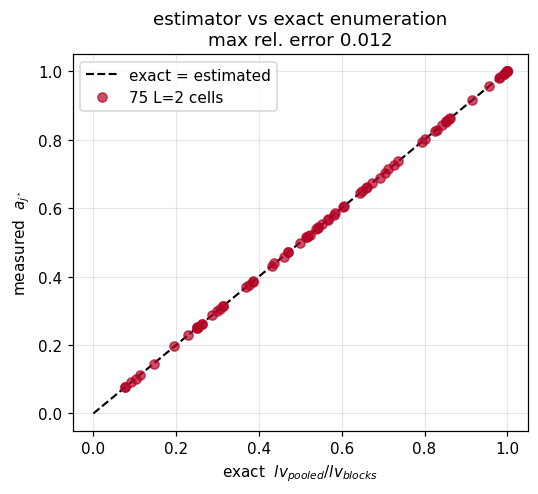

In [3]:
xs, ys = [], []
for r in good:
    if r['L'] != 2:
        continue
    g, a = exact.get((r['v'], r['m'], r['k'], r['rule_seed'])), aj(r, r['j_star'])
    if g and a is not None and g['lv_blocks']:
        xs.append(g['lv_pooled'] / g['lv_blocks']); ys.append(a)
xs, ys = np.array(xs), np.array(ys)
rel = np.abs(ys - xs) / np.maximum(xs, 1e-12)
print('check 1  a_{j*} vs exact enumeration: %d cells, max rel err %.3g, median %.3g'
      % (len(xs), rel.max(), np.median(rel)))

hit = miss = 0
for r in good:
    n = NK.get((r['v'], r['m'], r['s'], r['L'], r['k'], r['rule_seed']))
    if n is None:
        continue
    hit += (n == r['W_size']); miss += (n != r['W_size'])
print('check 2  |W| vs exact N_k: %d/%d exact, %d mismatched' % (hit, hit + miss, miss))
print('check 3  a_L over all saturated cells: min %.6f, max %.6f'
      % (min(aj(r, r['L']) for r in good), max(aj(r, r['L']) for r in good)))

fig, ax = plt.subplots(figsize=(5.0, 4.6), dpi=110)
ax.plot([0, 1], [0, 1], 'k--', lw=1.4, label='exact = estimated')
ax.plot(xs, ys, 'o', ms=6, color='#b40426', alpha=.7, label='%d L=2 cells' % len(xs))
ax.set_xlabel(r'exact  $lv_{pooled}/lv_{blocks}$'); ax.set_ylabel(r'measured  $a_{j^*}$')
ax.set_title('estimator vs exact enumeration\nmax rel. error %.2g' % rel.max())
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

## 3. The result: `a_j` profiles

Each line is one grammar. The dotted line marks `j*`, the deepest level the window contains
outright; `a_j = 1` at `j = L` is the saturation check. **The claim lives at `j = j*+1` and
beyond:** a value below 1 there means the window rejects grids that are already coherent at that
level, which a block-aligned reading of the same window could never do.

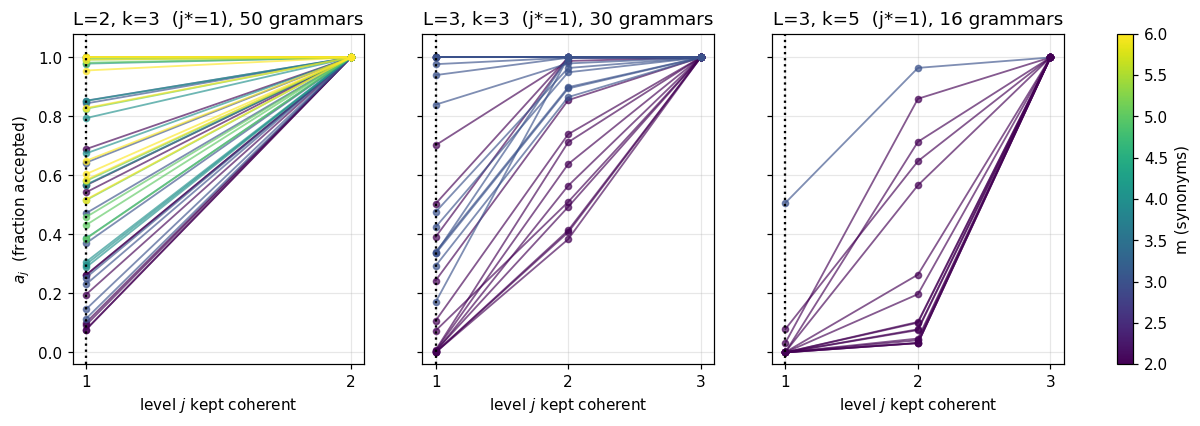

L=3, k=5 (j*=1): 16/16 grammars have a_2 < 0.99, median a_2 = 0.102, median a_1 = 0.000
   v=2: a_2 = 0.264, 0.567, 0.648, 0.714, 0.860, 0.965
   v=3: a_2 = 0.076, 0.078, 0.101, 0.103, 0.197
   v=4: a_2 = 0.031, 0.032, 0.032, 0.041, 0.047


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), dpi=110, sharey=True)
for ax, (L, k) in zip(axes, [(2, 3), (3, 3), (3, 5)]):
    sel = [r for r in good if r['L'] == L and r['k'] == k]
    for r in sel:
        js = sorted(int(j) for j in r['accept'])
        ax.plot(js, [r['accept'][str(j)] for j in js], 'o-', ms=4, lw=1.2, alpha=.65,
                color=plt.cm.viridis((r['m'] - 2) / 4.0))
    ax.axvline(sel[0]['j_star'], color='k', ls=':', lw=1.5)
    ax.set_xticks(range(1, L + 1)); ax.set_ylim(-.04, 1.08); ax.grid(alpha=.3)
    ax.set_xlabel('level $j$ kept coherent')
    ax.set_title('L=%d, k=%d  (j*=%d), %d grammars' % (L, k, sel[0]['j_star'], len(sel)))
axes[0].set_ylabel('$a_j$  (fraction accepted)')
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(2, 6))
fig.colorbar(sm, ax=axes, fraction=.02).set_label('m (synonyms)')
plt.show()

l3k5 = [r for r in good if r['L'] == 3 and r['k'] == 5 and aj(r, 2) is not None]
print('L=3, k=5 (j*=1): %d/%d grammars have a_2 < 0.99, median a_2 = %.3f, median a_1 = %.3f'
      % (sum(aj(r, 2) < .99 for r in l3k5), len(l3k5),
         np.median([aj(r, 2) for r in l3k5]), np.median([aj(r, 1) for r in l3k5])))
for v in (2, 3, 4):
    y = [aj(r, 2) for r in l3k5 if r['v'] == v]
    if y:
        print('   v=%d: a_2 = %s' % (v, ', '.join('%.3f' % t for t in sorted(y))))

## 4. "Depending on the synonym rules" -- the rule dependence hshunt predicted

The straddle signal is set by how constrained a boundary between two sibling blocks is, not by the
window size alone. Each extra synonym adds legal boundary pairs, so fewer scrambled pairings are
detectable; root detection `1 - a_{L-1}` should fall with `m`, and it does, monotonically. The
right panel shows that the *reach* itself is rule-dependent: at `L = 3, k = 3` the same window size
reaches the root on some grammars and stops at the blocks on others.

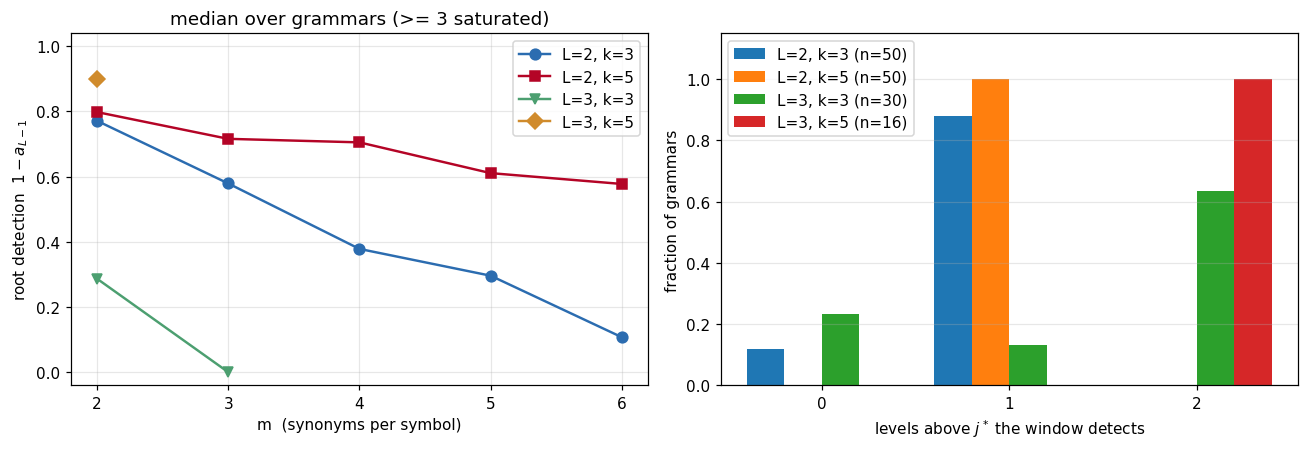

L=2 k=3: n=50   sees 0 levels up: 6    1: 44   2: 0  
L=2 k=5: n=50   sees 0 levels up: 0    1: 50   2: 0  
L=3 k=3: n=30   sees 0 levels up: 7    1: 4    2: 19 
L=3 k=5: n=16   sees 0 levels up: 0    1: 0    2: 16 

L=2 k=3 root detection by m: m=2 0.771, m=3 0.579, m=4 0.379, m=5 0.297, m=6 0.108


In [5]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12.0, 4.2), dpi=110)
ms = sorted({r['m'] for r in good})
for (L, k), mk, col in (((2, 3), 'o', '#2b6cb0'), ((2, 5), 's', '#b40426'),
                        ((3, 3), 'v', '#4c9f70'), ((3, 5), 'D', '#d08b2c')):
    med = []
    for m in ms:
        y = [root_strength(r) for r in good
             if (r['L'], r['k'], r['m']) == (L, k, m) and root_strength(r) is not None]
        # a median over one or two grammars is noise: the L=3, k=5, m=3 cells
        # mostly failed to saturate and are left out rather than plotted.
        med.append(np.median(y) if len(y) >= 3 else np.nan)
    axL.plot(ms, med, mk + '-', ms=7, lw=1.6, color=col, label='L=%d, k=%d' % (L, k))
axL.set_xlabel('m  (synonyms per symbol)'); axL.set_ylabel(r'root detection  $1 - a_{L-1}$')
axL.set_xticks(ms); axL.set_ylim(-.04, 1.04); axL.grid(alpha=.3); axL.legend()
axL.set_title('median over grammars (>= 3 saturated)')

groups = [(L, k) for L in (2, 3) for k in (3, 5)]
w = .8 / len(groups)
for i, (L, k) in enumerate(groups):
    sel = [r for r in good if r['L'] == L and r['k'] == k]
    u = [up(r) for r in sel]
    axR.bar([x + (i - len(groups) / 2 + .5) * w for x in sorted(set(u))],
            [u.count(x) / len(sel) for x in sorted(set(u))], w,
            label='L=%d, k=%d (n=%d)' % (L, k, len(sel)))
axR.set_xlabel('levels above $j^*$ the window detects'); axR.set_ylabel('fraction of grammars')
axR.set_xticks([0, 1, 2]); axR.set_ylim(0, 1.15); axR.grid(alpha=.3, axis='y'); axR.legend()
plt.tight_layout(); plt.show()

for L, k in groups:
    sel = [r for r in good if r['L'] == L and r['k'] == k]
    u = [up(r) for r in sel]
    print('L=%d k=%d: n=%-3d  sees 0 levels up: %-3d  1: %-3d  2: %-3d'
          % (L, k, len(sel), u.count(0), u.count(1), u.count(2)))
print()
print('L=2 k=3 root detection by m:',
      ', '.join('m=%d %.3f' % (m, np.median([root_strength(r) for r in good
                                             if (r['L'], r['k'], r['m']) == (2, 3, m)]))
                for m in ms))

## 5. Comparison against the previous best on this question

The previous measurement of the straddle effect is the exact `L = 2` enumeration in
`scripts/rhm_straddle.py` (commit `e990e0c`), which reports `straddle_gain = lv_blocks /
lv_aligned`: how many more grids a block-aligned reading accepts than the window machine does. It
established that the effect is real, but it could only ever see **one** level up, because at
`L = 2` with `j* = 1` the root is the only level above `j*`, and it could not be run at `L = 3` at
all (`v**64` grids).

The comparison below puts the two on the same footing at `L = 2` -- they agree -- and then states
what the new estimator adds, which is the `L = 3` row the old method cannot produce.

In [6]:
print('L=2, same cells, two methods for "does the window see above j*?"')
print('%-18s %-12s %-12s' % ('', 'exact', 'estimator'))
for k in (3, 5):
    sel = [r for r in good if r['L'] == 2 and r['k'] == k
           and (r['v'], r['m'], r['k'], r['rule_seed']) in exact]
    e = [exact[(r['v'], r['m'], r['k'], r['rule_seed'])] for r in sel]
    print('%-18s %-12.3f %-12.3f   (n=%d)'
          % ('k=%d  median a_j*' % k,
             np.median([g['lv_pooled'] / g['lv_blocks'] for g in e]),
             np.median([aj(r, r['j_star']) for r in sel]), len(sel)))
    print('%-18s %-12.3f %-12s'
          % ('      straddle_gain', np.median([g['straddle_gain'] for g in e]), '--'))

print()
print('what the new method adds -- the L=3 row, which enumeration cannot reach:')
for k in (3, 5):
    sel = [r for r in good if r['L'] == 3 and r['k'] == k]
    u = [up(r) for r in sel]
    print('  L=3 k=%d (j*=1): %d/%d grammars see TWO levels up (to the root); median a_2 = %.3f'
          % (k, u.count(2), len(sel), np.median([aj(r, 2) for r in sel if aj(r, 2) is not None])))
print()
print('max levels above j* visible at L=2, by construction: 1')
print('max levels above j* observed  at L=3:               %d'
      % max(up(r) for r in good if r['L'] == 3))

L=2, same cells, two methods for "does the window see above j*?"
                   exact        estimator   
k=3  median a_j*   0.574        0.575          (n=50)
      straddle_gain 1.913        --          
k=5  median a_j*   0.543        0.544          (n=25)
      straddle_gain 1.841        --          

what the new method adds -- the L=3 row, which enumeration cannot reach:
  L=3 k=3 (j*=1): 19/30 grammars see TWO levels up (to the root); median a_2 = 0.972
  L=3 k=5 (j*=1): 16/16 grammars see TWO levels up (to the root); median a_2 = 0.102

max levels above j* visible at L=2, by construction: 1
max levels above j* observed  at L=3:               2


## 6. Example traces

Two concrete grids make the mechanism legible. The first is a level-2-coherent `E_2` grid at
`L = 3`: every aligned `4x4` quadrant is a legal rendering of *some* level-2 symbol, but the four
quadrants were drawn independently, so there is no root that produces all four together. The second
is a genuinely grammatical grid. The trace prints, for each, which `5x5` windows fall outside `W` --
and for the `E_2` grid they sit on the quadrant boundaries, which is the whole claim.

In [7]:
import torch
from src.utils.random_hierarchy import RandomHierarchyModel2D
from scripts.rhm_straddle import window_codes
from scripts.rhm_straddle_levels import block_set, tile, window_set

dev = torch.device('cpu')
model = RandomHierarchyModel2D(v=2, s=2, L=3, m=2, seed=1000)
k = 5
W, n_used, _ = window_set(model, k, dev, 2000000, 50000)
print('W: %d distinct 5x5 windows from %.1fM grammatical grids (exact N_5 = %s)'
      % (W.numel(), n_used / 1e6, NK.get((2, 2, 2, 3, 5, 0))))

def trace(g, label):
    """Print a grid and mark the sites whose k x k window the machine has never seen."""
    c = window_codes(g[None], k, model.v, dev)[0]       # one window per predicted SITE
    i = torch.searchsorted(W, c.reshape(-1)).clamp(max=W.numel() - 1)
    bad = ~(W[i] == c.reshape(-1)).reshape(c.shape)
    print('\n%s' % label)
    for r in range(g.shape[0]):
        print(' '.join(('%d*' if bad[r, cc] else '%d ') % int(g[r, cc])
                       for cc in range(g.shape[1])), '  <- row %d' % r)
    print('(* = the 5x5 window centred here is not in W)')
    print('%d / %d windows unknown to the machine' % (int(bad.sum()), bad.numel()))
    ij = bad.nonzero()
    if len(ij):
        # the quadrant split is between sites 3 and 4; a 5x5 window centred at
        # (r, c) spans r-2..r+2, so it straddles the split iff r or c is in 2..5
        strad = sum(1 for a, b in ij if 2 <= int(a) <= 5 or 2 <= int(b) <= 5)
        print('%d of %d unknown windows straddle a 4x4 quadrant boundary' % (strad, len(ij)))

gen = torch.Generator(device=dev).manual_seed(20261103)
blocks = torch.as_tensor(block_set(model, 2), device=dev)
e2 = tile(blocks, 2, 1, dev, gen)[0]
trace(e2, 'E_2 grid: four INDEPENDENT legal 4x4 blocks (coherent to level 2, no common root)')

g, _ = model.sample(1, seed=90000)
trace(torch.as_tensor(np.asarray(g)[0], dtype=torch.int64), 'grammatical grid (E_3)')

W: 92080 distinct 5x5 windows from 0.7M grammatical grids (exact N_5 = 92080)

E_2 grid: four INDEPENDENT legal 4x4 blocks (coherent to level 2, no common root)
0  1  0  0  1  1  1  1    <- row 0
1  0  1  1  0  1  1  0    <- row 1
1  1  1  1  1  1  1  1    <- row 2
1  0  1  0  0  1* 1  0    <- row 3
1  1  1  1  1  1  0  0    <- row 4
0  1  1  0  1  0  1  1    <- row 5
0  0  0  1  1  1  1  1    <- row 6
1  1  1  0  1  0  1  0    <- row 7
(* = the 5x5 window centred here is not in W)
1 / 64 windows unknown to the machine
1 of 1 unknown windows straddle a 4x4 quadrant boundary

grammatical grid (E_3)
1  1  1  1  0  0  1  1    <- row 0
0  1  1  0  1  1  1  0    <- row 1
1  1  1  1  0  0  0  1    <- row 2
0  1  1  0  1  1  1  0    <- row 3
1  1  1  1  1  1  1  1    <- row 4
1  0  1  0  0  1  1  0    <- row 5
0  1  0  0  1  1  1  1    <- row 6
1  0  1  1  0  1  0  1    <- row 7
(* = the 5x5 window centred here is not in W)
0 / 64 windows unknown to the machine


## 7. What this does and does not show

**Shows.** The LS machine's translation-invariant window set is strictly stronger than a
block-aligned reading of the same window size, and the extra strength reaches **two** levels above
`j*` -- at `L = 3, k = 5` on all 16 saturated grammars, at `L = 3, k = 3` on 19 of 30. The strength
is rule-dependent and falls monotonically with the number of synonyms, so hshunt's "depending on
the synonym rules" is the correct caveat; what was not expected is the size, ~90% rejection at
`L = 3, k = 5` rather than a small signal.

**Does not show.** `a_j` is a statement about the **support** that the window set defines -- what a
machine with enough data to saturate `W` could reject. It is not what a finite-`P` LS sampler
actually emits, which is lower and is the subject of the sampling-complexity measurement
(`notebooks/rhm_sampling_complexity_2026-11-03.ipynb`): the reveal-one-site sampler drifts off the
valid set even when the set itself is correct.

**Limits of the measurement.**

* `k >= 7` is unreachable: the `int64` base-`(v+1)` window code overflows at `k*k = 49` digits for
  any `v >= 2`, and the script refuses rather than silently colliding codes. So the `L = 4` case,
  which would need `k = 15` to reach the root, is out of range for this method.
* 14 of 160 cells (all `L = 3, k = 5, m = 3`) never saturated `W` within 6M grammatical grids --
  `|W|` was still growing past 40M distinct windows. An unsaturated `W` rejects grammatical grids
  too, so `a_j` there is meaningless and those cells are excluded, not reported.
* `a_j` at `j < L` is Monte-Carlo over 200k tiled grids; the exact check in section 2 bounds the
  error at ~1% relative.